## 🔧 Constraints and Bounds

**Concepts:** [Problem options](../problem.md#problem-options) · [Which constraints each approach can enforce](../routers.md#which-constraints-each-approach-can-enforce) **Network/Router API:** [🔧 Options](hi31_options.ipynb)

The constraints on a network are stated once, in wind-farm terms, by [NetworkConstraints](../autoapi/optiwindnet/constraints/index.rst#optiwindnet.constraints.NetworkConstraints): topology, feeder route, feeder counts of the wind farm and of each substation, substation loads, balance and link length. Their form is checked on construction, independently of any problem.

[resolve()](../autoapi/optiwindnet/constraints/index.rst#optiwindnet.constraints.NetworkConstraints.resolve) checks them against a problem instance — a graph `A` and a cable capacity, given as to the optimizers (`capacity` in inflow, or `capacity_nominal` in the unit of the turbine power, which is then quantized) — and returns a [NetworkBounds](../autoapi/optiwindnet/constraints/index.rst#optiwindnet.constraints.NetworkBounds), the same constraints in the terms the optimizers use:

- feeder counts are in feeders (substation connections), with `groups_lb` and `groups_ub` giving the corresponding numbers of subtrees or rings;
- per-substation values are per root, in root order (`-R` to `-1`);
- loads are in integer inflow.

Every check that involves the instance happens there, so that no optimizer starts on constraints that cannot all be met. `set_problem(constraints=...)` and [hgs_cvrp(constraints=...)](../autoapi/optiwindnet/baselines/hgs/index.rst#optiwindnet.baselines.hgs.hgs_cvrp) resolve the constraints themselves, with the quantization of their solve. The bounds themselves are taken by the lower-level MILP model builders and by [clusterize()](../autoapi/optiwindnet/clustering/index.rst#optiwindnet.clustering.clusterize).

### Setup

_Neart na Gaoithe_ has 54 turbines and two substations; the cables hold 7 turbines.

In [1]:
from prettyTables import Table

from optiwindnet.baselines.hgs import hgs_cvrp
from optiwindnet.clustering import clusterize
from optiwindnet.constraints import NetworkConstraints
from optiwindnet.importer import load_repository
from optiwindnet.interarraylib import links_over_length
from optiwindnet.loads import set_terminal_power
from optiwindnet.mesh import make_planar_embedding
from optiwindnet.MILP import solver_factory
from optiwindnet.svg import svgplot
from optiwindnet.transforming import as_normalized

In [2]:
L = load_repository().neart
P, A = make_planar_embedding(L)
T, R = A.graph['T'], A.graph['R']
capacity = 7
T, R

(54, 2)

A helper lists the fields of a [NetworkBounds](../autoapi/optiwindnet/constraints/index.rst#optiwindnet.constraints.NetworkBounds):

In [3]:
def show(bounds):
    fields = (
        'topology', 'feeder_route', 'feeders_per_group', 'feeders_lb',
        'feeders_ub', 'groups_lb', 'groups_ub', 'root_feeders_lb',
        'root_feeders_ub', 'root_load_ub', 'group_load_lb', 'group_load_ub',
    )  # fmt: skip
    return Table([(name, getattr(bounds, name)) for name in fields])

### The constraints

[NetworkConstraints](../autoapi/optiwindnet/constraints/index.rst#optiwindnet.constraints.NetworkConstraints) is an immutable value: strings are coerced to enums, sequences to tuples, and it can be compared and hashed. `help(NetworkConstraints)` documents every field.

In [4]:
constraints = NetworkConstraints(
    topology='radial', max_feeders='min+1', max_substation_feeders=[None, 5]
)
constraints

NetworkConstraints(topology=<Topology.RADIAL: 'radial'>, feeder_route=<FeederRoute.SEGMENTED: 'segmented'>, feeders=None, max_feeders='min+1', substation_feeders=None, max_substation_feeders=(None, 5), max_substation_loads=None, balanced=False, max_link_length=None)

Errors that do not depend on the instance are raised on construction:

In [5]:
for kwargs in (
    {'feeders': 9, 'max_feeders': 10},  # exact or at most, not both
    {'topology': 'ringed', 'feeders': 9},  # a ring has two feeders
    {'max_feeders': 'minimum'},  # 'min' or 'min+k'
    {'substation_feeders': 4, 'max_substation_feeders': 5},  # one or the other
):
    try:
        NetworkConstraints(**kwargs)
    except ValueError as exc:
        print(f'{kwargs}: {exc}')

{'feeders': 9, 'max_feeders': 10}: Give either feeders or max_feeders, not both.
{'topology': 'ringed', 'feeders': 9}: feeders (9) must count an even number of feeders for a RINGED topology (each ring has two feeders).
{'max_feeders': 'minimum'}: max_feeders must be a positive integer, 'min' or 'min+k': got 'minimum'.
{'substation_feeders': 4, 'max_substation_feeders': 5}: A substation may have either substation_feeders or max_substation_feeders, not both.


### Resolving the constraints

Without constraints, only the capacity minimum bounds the feeder count from below: `ceil(T / capacity)`. No upper bound is given (`feeders_ub` is `None`), and no root is bounded.

In [6]:
show(NetworkConstraints().resolve(A, capacity=capacity))

column 1,column 2
topology,branched
feeder_route,segmented
feeders_per_group,1
feeders_lb,8
feeders_ub,
groups_lb,8
groups_ub,
root_feeders_lb,
root_feeders_ub,
root_load_ub,


#### The feeder count of the wind farm

`feeders` fixes the count and `max_feeders` bounds it from above, either as an integer or relative to the minimum (`'min'`, `'min+k'`). Below the minimum, or above one feeder per turbine, the count is refused.

In [7]:
rows = []
for kwargs in (
    {'feeders': 'min'},
    {'feeders': 10},
    {'max_feeders': 'min+2'},
    {'max_feeders': 12},
):
    bounds = NetworkConstraints(**kwargs).resolve(A, capacity=capacity)
    rows.append((kwargs, bounds.feeders_lb, bounds.feeders_ub))
Table(rows, headers=('constraints', 'feeders_lb', 'feeders_ub'))

constraints,feeders_lb,feeders_ub
{'feeders': 'min'},8,8
{'feeders': 10},10,10
{'max_feeders': 'min+2'},8,10
{'max_feeders': 12},8,12


A ring has two feeders, so a ringed topology counts both. Here the capacity bounds each arm of a ring, so a ring holds up to twice as many turbines as a subtree, and `groups_lb` counts rings.

In [8]:
show(
    NetworkConstraints(topology='ringed', max_feeders='min+2').resolve(
        A, capacity=capacity
    )
)

column 1,column 2
topology,ringed
feeder_route,segmented
feeders_per_group,2
feeders_lb,8
feeders_ub,10
groups_lb,4
groups_ub,5
root_feeders_lb,
root_feeders_ub,
root_load_ub,


#### The feeders of each substation

Per-substation counts are given for every substation at once (a scalar) or one by one (a sequence, `None` for free). They must be compatible with the count of the wind farm: the sums of their minima and maxima must leave a count within the wind farm's range, which they narrow.

In [9]:
for kwargs in (
    {'max_substation_feeders': 5},
    {'max_substation_feeders': (None, 4)},
    {'substation_feeders': (5, 4)},
    {'substation_feeders': (None, 4), 'max_substation_feeders': (6, None)},
):
    bounds = NetworkConstraints(**kwargs).resolve(A, capacity=capacity)
    print(
        f'{kwargs}\n'
        f'    roots: {bounds.root_feeders_lb} to {bounds.root_feeders_ub}; '
        f'wind farm: {bounds.feeders_lb} to {bounds.feeders_ub}'
    )

{'max_substation_feeders': 5}
    roots: None to (5, 5); wind farm: 8 to 10
{'max_substation_feeders': (None, 4)}
    roots: None to (None, 4); wind farm: 8 to None
{'substation_feeders': (5, 4)}
    roots: (5, 4) to (5, 4); wind farm: 9 to 9
{'substation_feeders': (None, 4), 'max_substation_feeders': (6, None)}
    roots: (0, 4) to (6, 4); wind farm: 8 to 10


#### The load of each substation

`max_substation_loads` is in the unit of the turbine power. Without a unit, it is in inflow — here, turbines. With a unit, `resolve()` quantizes the turbine power for `capacity_nominal` (see [Mixed power](lo16_mixed_power.ipynb)) and rounds each limit down to whole inflow. A copy of `A` with 8 MW turbines and 56 MW cables shows it:

In [10]:
A_mw = A.copy()
set_terminal_power(A_mw, [8.0] * T, power_unit='MW')
constraints = NetworkConstraints(max_substation_loads=(None, 180.0))
constraints.resolve(A_mw, capacity_nominal=56.0).root_load_ub

(None, 22)

#### Balance

`balanced` bounds the load of every subtree (or ring) of the wind farm to the two integers around the average, so it needs a fixed feeder count.

In [11]:
show(NetworkConstraints(feeders=9, balanced=True).resolve(A, capacity=capacity))

column 1,column 2
topology,branched
feeder_route,segmented
feeders_per_group,1
feeders_lb,9
feeders_ub,9
groups_lb,9
groups_ub,9
root_feeders_lb,
root_feeders_ub,
root_load_ub,


#### Constraints that cannot all be met

`resolve()` raises `ValueError` with the reason when the constraints do not suit the instance:

In [12]:
for kwargs in (
    {'max_feeders': 6},  # below the minimum
    {'substation_feeders': (5, 5), 'feeders': 8},  # the counts sum to 10, not 8
    {'max_substation_feeders': (2, 2)},  # 4 feeders cannot carry 54 turbines
    {'max_substation_loads': (25, 25)},  # room for 50 turbines only
    {'balanced': True},  # the feeder count is not fixed
    {'substation_feeders': (None, 3), 'max_substation_loads': (None, 2)},
):
    try:
        NetworkConstraints(**kwargs).resolve(A, capacity=capacity)
    except ValueError as exc:
        print(f'{kwargs}: {exc}')

{'max_feeders': 6}: max_feeders (6) is below the minimum necessary (8).
{'substation_feeders': (5, 5), 'feeders': 8}: The substation feeder counts allow between 10 and 10 feeders, outside the range for the wind farm (8 to 8).
{'max_substation_feeders': (2, 2)}: The substation limits hold a load of 28, less than the total (54).
{'max_substation_loads': (25, 25)}: The substation limits hold a load of 50, less than the total (54).
{'balanced': True}: balanced requires a fixed feeder count: give feeders (e.g. feeders='min'), or substation_feeders for every substation.
{'substation_feeders': (None, 3), 'max_substation_loads': (None, 2)}: Substation -1 needs 3 feeders, more than its load limit can supply.


A count relative to the minimum is refused with unequal turbine power: that minimum treats a turbine as divisible among feeders, so it may not be attainable.

In [13]:
A_heavy = A.copy()
A_heavy.nodes[0]['inflow'] = 2
try:
    NetworkConstraints(feeders='min').resolve(A_heavy, capacity=capacity)
except ValueError as exc:
    print(exc)

feeders cannot be relative to the minimum with unequal turbine power: the minimum may not be attainable.


### The bounds at work

Two substation limits serve as the example: at most 5 feeders and 26 turbines for the second substation.

In [14]:
limits = NetworkConstraints(
    max_substation_feeders=(None, 5), max_substation_loads=(None, 26)
)
bounds = limits.resolve(A, capacity=capacity)


def per_root(S):
    return Table(
        [(r, S.degree[r], S.nodes[r]['load']) for r in range(-R, 0)],
        headers=('root', 'feeders', 'turbines'),
    )

#### Clustering

With several substations, [hgs_cvrp()](../autoapi/optiwindnet/baselines/hgs/index.rst#optiwindnet.baselines.hgs.hgs_cvrp) first assigns the turbines to substations with [clusterize()](../autoapi/optiwindnet/clustering/index.rst#optiwindnet.clustering.clusterize), which takes the bounds and the most turbines a group may hold (here, a subtree: `capacity`). Given the bounds, each root gets a number of routes within its own bounds, and only as many turbines as those routes and its load limit allow:

In [15]:
Table(
    [
        (r, len(free), len(capped))
        for r, free, capped in zip(
            range(-R, 0), clusterize(A, capacity), clusterize(A, capacity, bounds)
        )
    ],
    headers=('root', 'turbines (no bounds)', 'turbines (bounds)'),
)

root,turbines (no bounds),turbines (bounds)
-2,21,28
-1,33,26


#### HGS-CVRP

[hgs_cvrp()](../autoapi/optiwindnet/baselines/hgs/index.rst#optiwindnet.baselines.hgs.hgs_cvrp) takes the constraints and resolves them itself; its solution keeps their bounds, and records the per-root bounds in its `solver_details`:

In [16]:
S_hgs = hgs_cvrp(
    as_normalized(A), capacity=capacity, time_limit=1, constraints=limits, seed=1234567
)
S_hgs.graph['solver_details']

{'seed': 1234567,
 'vehicles': [None, 5],
 'root_feeders_ub': (None, 5),
 'root_load_ub': (None, 26)}

In [17]:
per_root(S_hgs)

root,feeders,turbines
-2,4,28
-1,5,26


HGS-CVRP can only bound the number of routes from above. A count that must be exact — fixed above the minimum, or the exact count of a substation — is held by solving those routes with slack nodes that fill each route to a balanced load, so that no route can be left empty. Balance itself applies across all substations: each root takes as many turbines as its routes can hold at the balanced loads of the whole wind farm.

In [18]:
balanced = NetworkConstraints(substation_feeders=(5, 4), balanced=True)
S_bal = hgs_cvrp(
    as_normalized(A),
    capacity=capacity,
    time_limit=1,
    constraints=balanced,
    seed=1234567,
)
Table(
    [
        (r, str(sorted(S_bal.nodes[n]['load'] for n in S_bal.neighbors(r))))
        for r in range(-R, 0)
    ],
    headers=('root', 'subtree loads'),
)

root,subtree loads
-2,"[6, 6, 6, 6, 6]"
-1,"[6, 6, 6, 6]"


#### MILP

`set_problem(constraints=...)` resolves the constraints after quantizing the turbine power, and keeps both: `solver.constraints` and `solver.bounds`. The model gets the bound rows; with any root bounded, it keeps every feeder to every root, and the detours keep each subtree on its root. Here [hgs_cvrp()](../autoapi/optiwindnet/baselines/hgs/index.rst#optiwindnet.baselines.hgs.hgs_cvrp)'s solution warm-starts it.

In [19]:
solver = solver_factory('ortools.cp_sat')
solver.set_problem(P, A, capacity=capacity, constraints=limits, warmstart=S_hgs)
solver.bounds == bounds

True

In [20]:
solver.solve(time_limit=10, mip_gap=0.01, options={'random_seed': 1234567})
S_milp, G_milp = solver.get_solution()
per_root(S_milp)

root,feeders,turbines
-2,4,28
-1,5,26


The solution records the topology, feeder route and balance among its method options, and the count bounds among its solver details:

In [21]:
{
    key: G_milp.graph['method_options'][key]
    for key in ('topology', 'feeder_route', 'balanced')
}

{'topology': <Topology.BRANCHED: 'branched'>,
 'feeder_route': <FeederRoute.SEGMENTED: 'segmented'>,
 'balanced': False}

In [22]:
G_milp.graph['solver_details']

{'random_seed': 1234567,
 'feeders_lb': 8,
 'root_feeders_ub': (None, 5),
 'root_load_ub': (None, 26),
 'strategy': 'FEASIBLE'}

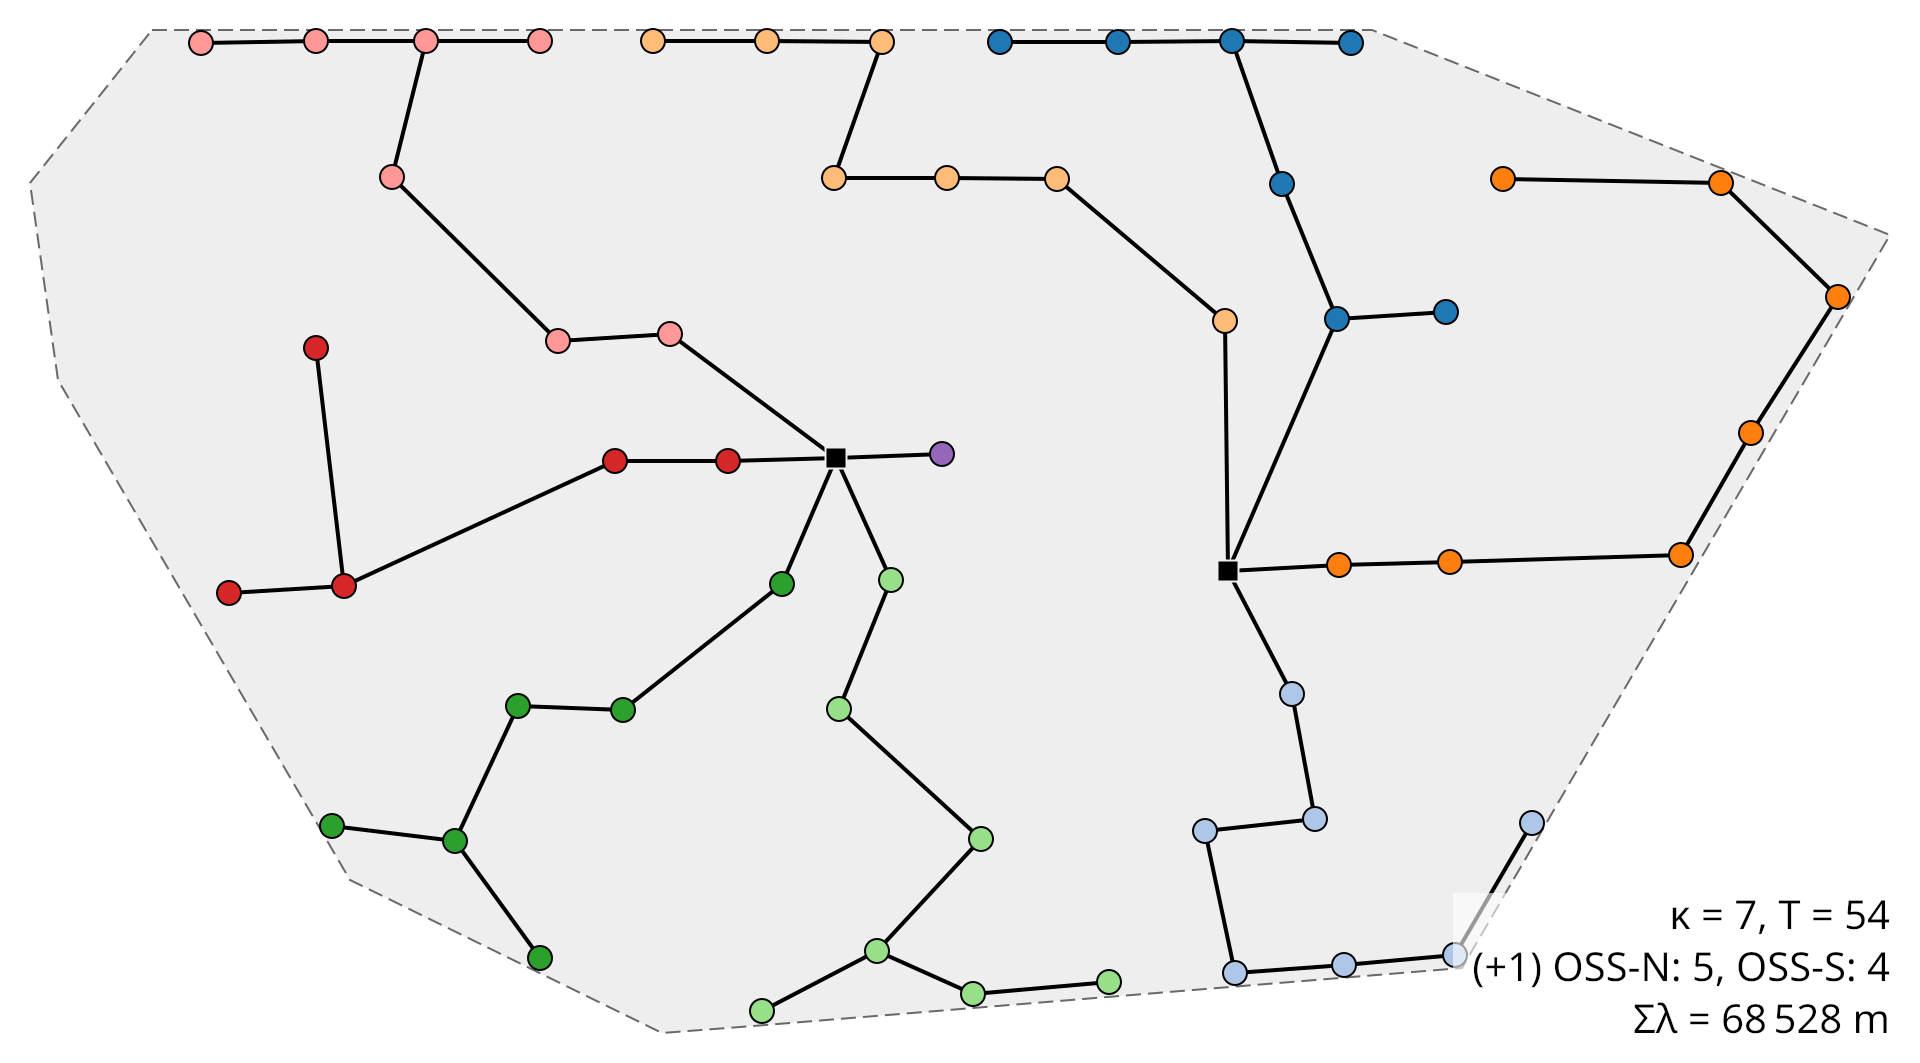

In [23]:
svgplot(G_milp)

### The link length

`max_link_length` limits the maximum routed length of available links and feeders as recorded in `A`. Those lengths account for obstacle contours, while detours are not yet known in `A`. The limit resolves to the `link_length_ub` of the bounds, scaled along with a normalized `A`; `A` itself is left unchanged. `resolve()` also refuses a limit out of scale for the site: one that leaves a turbine without any available link or feeder within it, or fewer turbines with a feeder within it than the subtrees or rings needed:

In [24]:
short = NetworkConstraints(max_link_length=2300)
print(short.resolve(A, capacity=capacity).link_length_ub)
try:
    NetworkConstraints(max_link_length=1000).resolve(A, capacity=capacity)
except ValueError as exc:
    print(exc)

2300.0
max_link_length leaves 19 turbine(s) without any link or feeder within it: [0, 1, 5, 8, 9, 10, 11, 14, 17, 19]...


HGS-CVRP gives the links and feeders over the limit the cost of a link absent from `A`, but does not forbid them: if its solution still uses one, it raises `ValueError`. Here its radial routes cannot keep the limit:

In [25]:
try:
    hgs_cvrp(
        as_normalized(A),
        capacity=capacity,
        time_limit=1,
        constraints=short,
        seed=1234567,
    )
except ValueError as exc:
    print(exc)

HGS-CVRP found no solution within the link length limit: 1 link(s) exceed it, e.g. (-1, 20).


The MILP model fixes available links and feeders over the limit to zero. Detours created after the solve may still stretch a link past it: [links_over_length()](../autoapi/optiwindnet/interarraylib/index.rst#optiwindnet.interarraylib.links_over_length) lists the links of the final routed network whose routes exceed the limit (none here).

In [26]:
solver_short = solver_factory('ortools.cp_sat')
solver_short.set_problem(P, A, capacity=capacity, constraints=short)
solver_short.solve(time_limit=10, mip_gap=0.01, options={'random_seed': 1234567})
S_short, G_short = solver_short.get_solution()
links_over_length(G_short, short.max_link_length)

[]

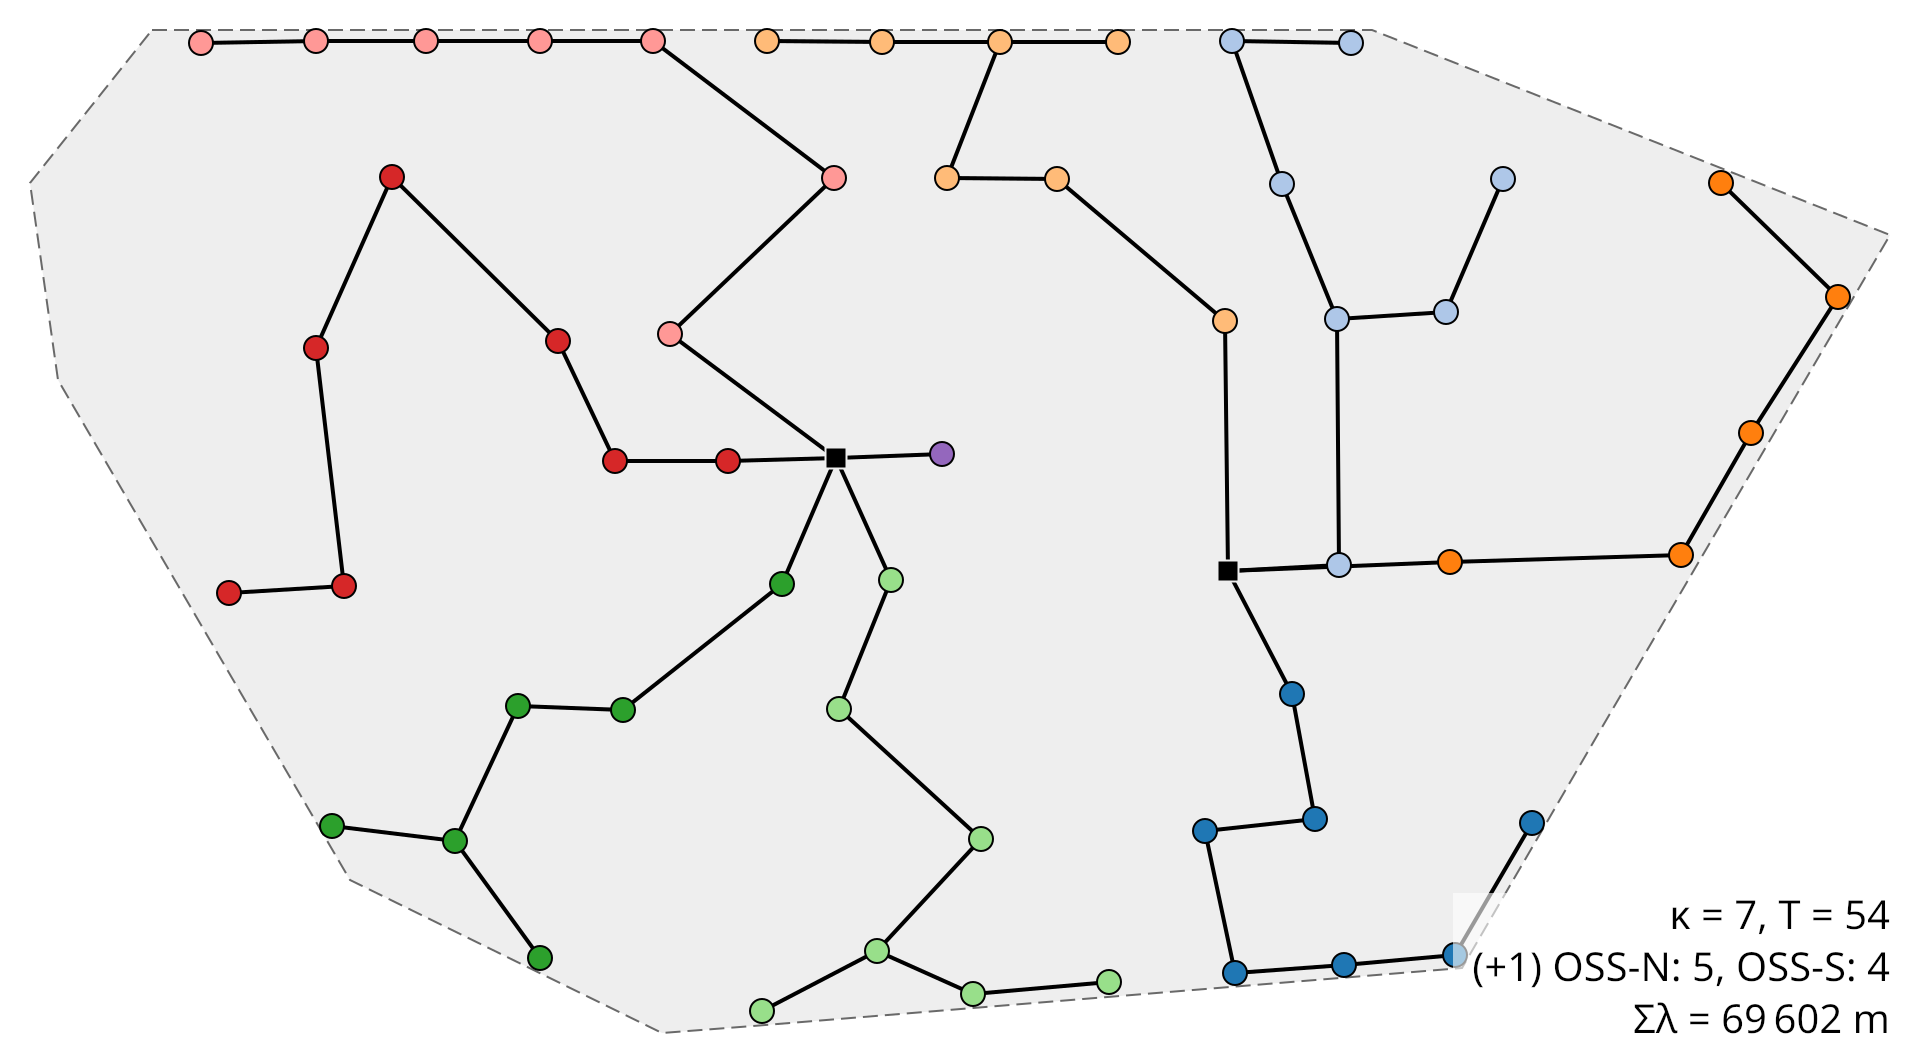

In [27]:
svgplot(G_short)